In [1]:
import pandas as pd
import numpy as np

edges = pd.read_csv('../ogbn_arxiv_dataset/edges_subset.csv')
edges.head()

,src_node_id,dst_node_id,relevant,cosine_similarity,cosine_score_min_max,cosine_score_mean,cosine_score_softmax,centroid_cosine_distance
0,146049,88765,True,0.608752,1.000000,0.708837,0.275808,0.057397
1,146049,157722,False,0.538599,0.310109,0.637791,0.193345,0.101759
2,146049,95518,True,0.646419,0.000000,0.605855,0.164810,0.121700
3,146049,160459,False,0.584842,0.178752,0.624263,0.180700,0.110205
4,146049,51364,False,0.596761,0.227963,0.629331,0.185337,0.107041


In [ ]:
# drop rows where any score is missing
score_cols = ['cosine_score_min_max', 'cosine_score_mean', 'cosine_score_softmax', 'centroid_cosine_distance']
df = edges.dropna(subset=['cosine_similarity'] + score_cols).copy()
print(f'Rows used: {len(df)} / {len(edges)}')

KeyError: ['cosine_score_softmax, centroid_cosine_distance']

In [ ]:
results = {}
for col in score_cols:
    mad = (df['cosine_similarity'] - df[col]).abs().mean()
    results[col] = mad

results_df = pd.DataFrame.from_dict(results, orient='index', columns=['MAD'])
results_df.index.name = 'score'
results_df

,MAD
score,
cosine_score_min_max,0.223481
cosine_score_mean,0.073899
cosine_score_softmax,0.524762


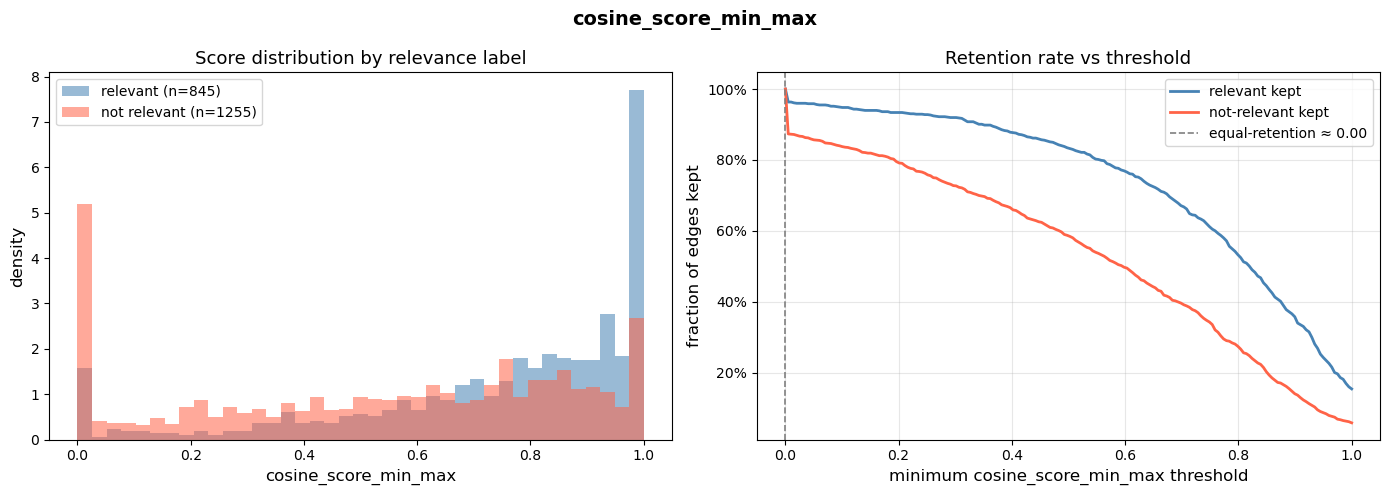

Equal-retention threshold: 0.000
  relevant kept:     100.0%
  not-relevant kept: 100.0%



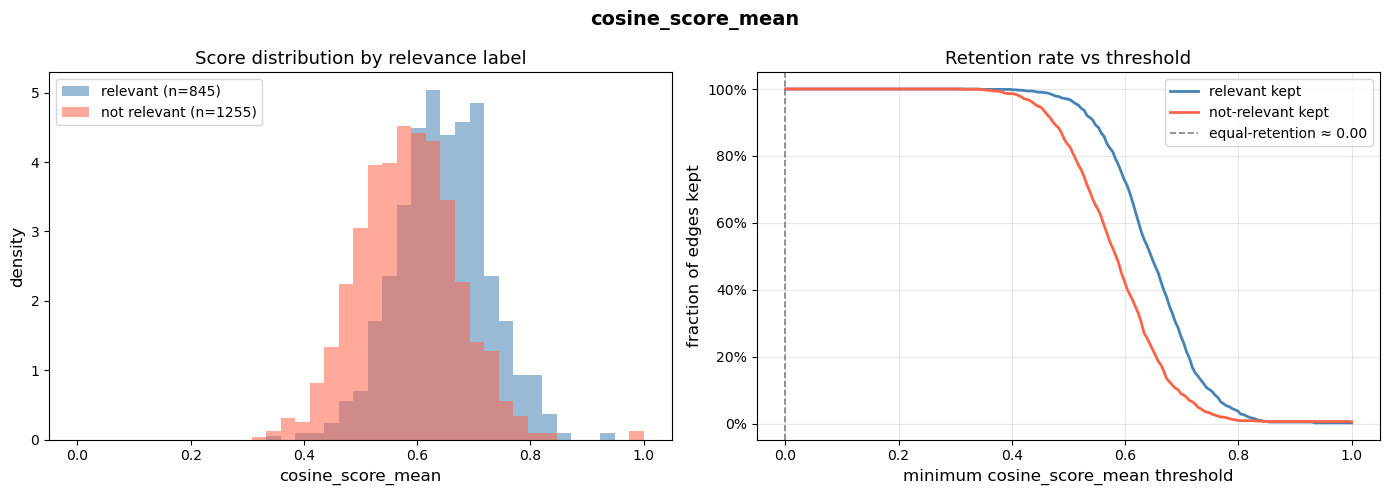

Equal-retention threshold: 0.000
  relevant kept:     100.0%
  not-relevant kept: 100.0%



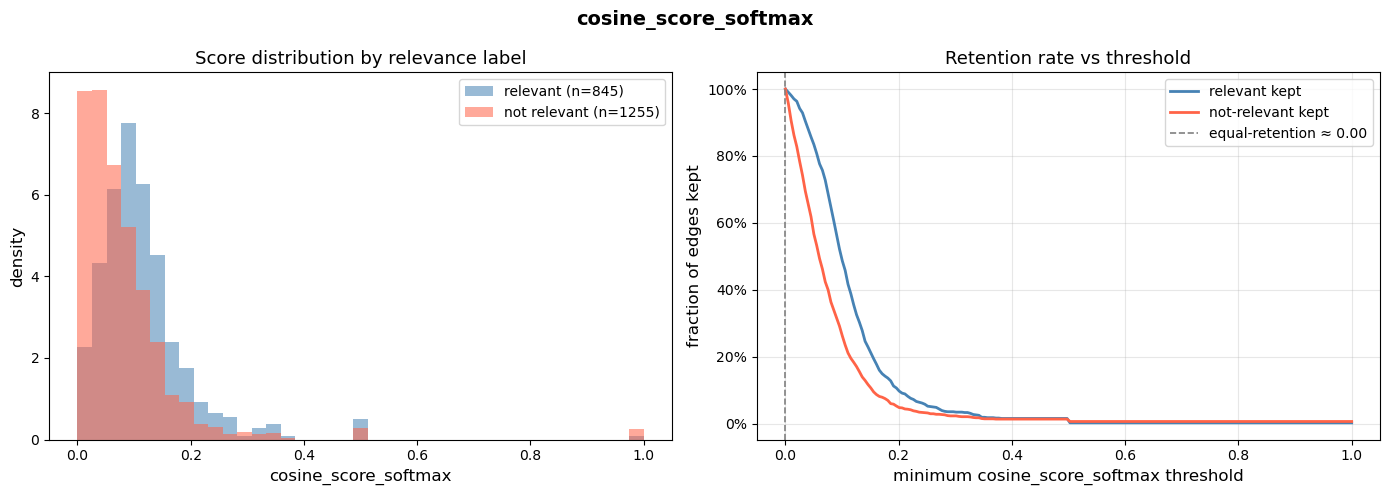

Equal-retention threshold: 0.000
  relevant kept:     100.0%
  not-relevant kept: 100.0%



In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# keep only rows with a known relevant label
plot_df = df.dropna(subset=['relevant']).copy()
plot_df['relevant'] = plot_df['relevant'].astype(bool)

thresholds = np.linspace(0, 1, 200)

for score_col in score_cols:
    relevant     = plot_df.loc[plot_df['relevant'],  score_col].values
    not_relevant = plot_df.loc[~plot_df['relevant'], score_col].values

    kept_relevant     = np.array([(relevant     >= t).mean() for t in thresholds])
    kept_not_relevant = np.array([(not_relevant >= t).mean() for t in thresholds])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(score_col, fontsize=14, fontweight='bold')

    # --- left: distribution ---
    ax = axes[0]
    bins = np.linspace(0, 1, 40)
    ax.hist(relevant,     bins=bins, alpha=0.55, color='steelblue', density=True, label=f'relevant (n={len(relevant)})')
    ax.hist(not_relevant, bins=bins, alpha=0.55, color='tomato',    density=True, label=f'not relevant (n={len(not_relevant)})')
    ax.set_xlabel(score_col, fontsize=12)
    ax.set_ylabel('density', fontsize=12)
    ax.set_title('Score distribution by relevance label', fontsize=13)
    ax.legend(fontsize=10)

    # --- right: retention rate vs threshold ---
    ax2 = axes[1]
    ax2.plot(thresholds, kept_relevant,     color='steelblue', lw=2, label='relevant kept')
    ax2.plot(thresholds, kept_not_relevant, color='tomato',    lw=2, label='not-relevant kept')
    ax2.set_xlabel(f'minimum {score_col} threshold', fontsize=12)
    ax2.set_ylabel('fraction of edges kept', fontsize=12)
    ax2.set_title('Retention rate vs threshold', fontsize=13)
    ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax2.legend(fontsize=10)
    ax2.grid(alpha=0.3)

    diff = np.abs(kept_relevant - kept_not_relevant)
    cross_idx = diff.argmin()
    cross_t   = thresholds[cross_idx]
    ax2.axvline(cross_t, color='gray', linestyle='--', lw=1.2,
                label=f'equal-retention ≈ {cross_t:.2f}')
    ax2.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

    print(f'Equal-retention threshold: {cross_t:.3f}')
    print(f'  relevant kept:     {kept_relevant[cross_idx]:.1%}')
    print(f'  not-relevant kept: {kept_not_relevant[cross_idx]:.1%}')
    print()

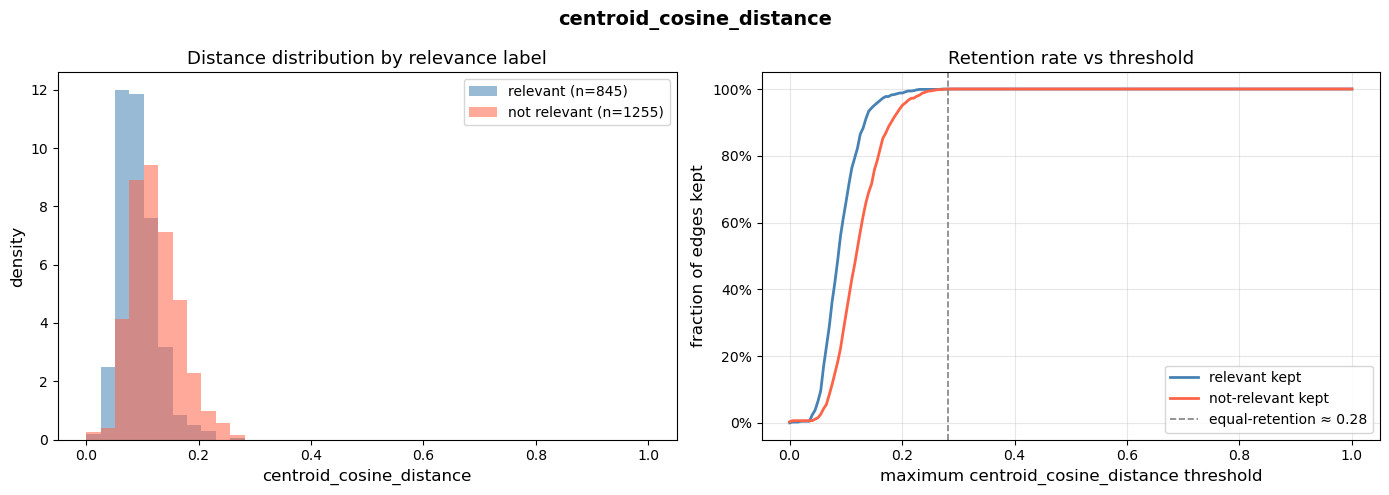

Equal-retention threshold: 0.281
  relevant kept:     100.0%
  not-relevant kept: 100.0%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# cosine distance retention rate: centroid_cosine_distance is a DISTANCE,
# so "kept" means distance <= threshold (close to the centroid), unlike the
# similarity scores above where "kept" means score >= threshold.
distance_col = 'centroid_cosine_distance'

relevant     = plot_df.loc[plot_df['relevant'],  distance_col].values
not_relevant = plot_df.loc[~plot_df['relevant'], distance_col].values

thresholds_d = np.linspace(0, 1, 200)

kept_relevant     = np.array([(relevant     <= t).mean() for t in thresholds_d])
kept_not_relevant = np.array([(not_relevant <= t).mean() for t in thresholds_d])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(distance_col, fontsize=14, fontweight='bold')

# --- left: distribution ---
ax = axes[0]
bins = np.linspace(0, 1, 40)
ax.hist(relevant,     bins=bins, alpha=0.55, color='steelblue', density=True, label=f'relevant (n={len(relevant)})')
ax.hist(not_relevant, bins=bins, alpha=0.55, color='tomato',    density=True, label=f'not relevant (n={len(not_relevant)})')
ax.set_xlabel(distance_col, fontsize=12)
ax.set_ylabel('density', fontsize=12)
ax.set_title('Distance distribution by relevance label', fontsize=13)
ax.legend(fontsize=10)

# --- right: retention rate vs threshold ---
ax2 = axes[1]
ax2.plot(thresholds_d, kept_relevant,     color='steelblue', lw=2, label='relevant kept')
ax2.plot(thresholds_d, kept_not_relevant, color='tomato',    lw=2, label='not-relevant kept')
ax2.set_xlabel(f'maximum {distance_col} threshold', fontsize=12)
ax2.set_ylabel('fraction of edges kept', fontsize=12)
ax2.set_title('Retention rate vs threshold', fontsize=13)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

diff = np.abs(kept_relevant - kept_not_relevant)
cross_idx = diff.argmin()
cross_t   = thresholds_d[cross_idx]
ax2.axvline(cross_t, color='gray', linestyle='--', lw=1.2,
            label=f'equal-retention ≈ {cross_t:.2f}')
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

print(f'Equal-retention threshold: {cross_t:.3f}')
print(f'  relevant kept:     {kept_relevant[cross_idx]:.1%}')
print(f'  not-relevant kept: {kept_not_relevant[cross_idx]:.1%}')


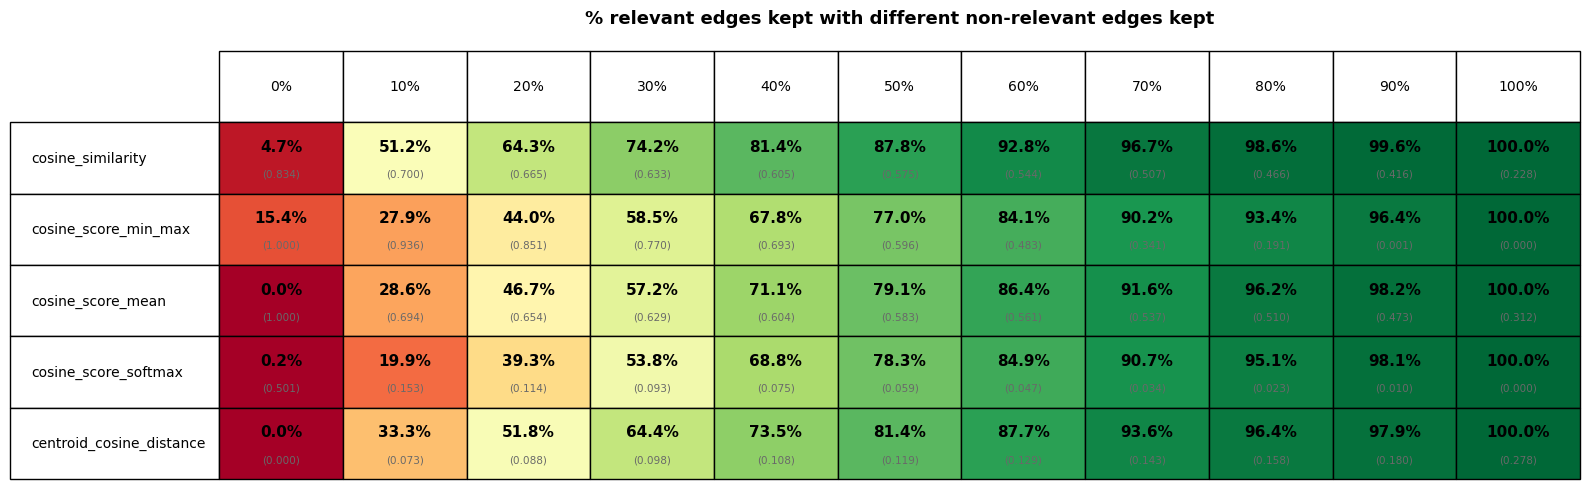

,0%,10%,20%,30%,40%,50%,60%,70%,80%,90%,100%
cosine_similarity,4.7,51.2,64.3,74.2,81.4,87.8,92.8,96.7,98.6,99.6,100.0
cosine_score_min_max,15.4,27.9,44.0,58.5,67.8,77.0,84.1,90.2,93.4,96.4,100.0
cosine_score_mean,0.0,28.6,46.7,57.2,71.1,79.1,86.4,91.6,96.2,98.2,100.0
cosine_score_softmax,0.2,19.9,39.3,53.8,68.8,78.3,84.9,90.7,95.1,98.1,100.0
centroid_cosine_distance,0.0,33.3,51.8,64.4,73.5,81.4,87.7,93.6,96.4,97.9,100.0


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Summary table: rows are filtering metrics, columns are the % of
# not-relevant references kept (0% - 100%, step 10%), cells are the
# % of relevant references kept (bold) at the threshold (smaller, in
# brackets) that achieves that not-relevant retention rate.
metric_cols = [
    'cosine_similarity',
    'cosine_score_min_max',
    'cosine_score_mean',
    'cosine_score_softmax',
    'centroid_cosine_distance',
]

# centroid_cosine_distance is a distance (lower = more similar), so it is
# thresholded with <=, opposite of the similarity/score columns which use >=
distance_metrics = {'centroid_cosine_distance'}

not_relevant_targets = np.arange(0, 101, 10)  # 0, 10, ..., 100

summary_table   = pd.DataFrame(index=metric_cols, columns=[f'{p}%' for p in not_relevant_targets], dtype=float)
threshold_table = pd.DataFrame(index=metric_cols, columns=[f'{p}%' for p in not_relevant_targets], dtype=float)

for col in metric_cols:
    relevant     = plot_df.loc[plot_df['relevant'],  col].values
    not_relevant = plot_df.loc[~plot_df['relevant'], col].values

    lo = float(min(relevant.min(), not_relevant.min()))
    hi = float(max(relevant.max(), not_relevant.max()))
    thresholds = np.linspace(lo, hi, 1000)

    if col in distance_metrics:
        kept_relevant     = np.array([(relevant     <= t).mean() for t in thresholds])
        kept_not_relevant = np.array([(not_relevant <= t).mean() for t in thresholds])
    else:
        kept_relevant     = np.array([(relevant     >= t).mean() for t in thresholds])
        kept_not_relevant = np.array([(not_relevant >= t).mean() for t in thresholds])

    for p in not_relevant_targets:
        idx = np.abs(kept_not_relevant * 100 - p).argmin()
        summary_table.loc[col, f'{p}%']   = kept_relevant[idx] * 100
        threshold_table.loc[col, f'{p}%'] = thresholds[idx]

summary_table = summary_table.round(1)
threshold_table = threshold_table.round(3)

# --- render as a colored table diagram ---
fig, ax = plt.subplots(figsize=(16, 0.7 * len(metric_cols) + 1.5))
ax.axis('off')

norm = plt.Normalize(vmin=0, vmax=100)
cmap = plt.cm.RdYlGn
cell_colors = [[cmap(norm(v)) for v in row] for row in summary_table.values]

blank_text = [['' for _ in row] for row in summary_table.values]

tbl = ax.table(
    cellText=blank_text,
    rowLabels=summary_table.index,
    colLabels=summary_table.columns,
    cellColours=cell_colors,
    loc='center',
    cellLoc='center',
    bbox=[0, 0, 1, 1],
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
fig.canvas.draw()  # force layout so cell.get_x()/get_y() reflect final (bbox-scaled) positions

# two-line cell content: bold percentage on top, smaller threshold below
nrows, ncols = summary_table.shape
for i in range(nrows):
    for j in range(ncols):
        cell = tbl[(i + 1, j)]
        x = cell.get_x() + cell.get_width() / 2
        y = cell.get_y() + cell.get_height() / 2
        h = cell.get_height()

        pct = summary_table.values[i, j]
        thr = threshold_table.values[i, j]

        ax.text(
            x, y + h * 0.16, f'{pct:.1f}%',
            transform=ax.transAxes, ha='center', va='center',
            fontsize=11, fontweight='bold',
        )
        ax.text(
            x, y - h * 0.22, f'({thr:.3f})',
            transform=ax.transAxes, ha='center', va='center',
            fontsize=7.5, color='dimgray',
        )

ax.set_title(
    '% relevant edges kept with different non-relevant edges kept',
    fontsize=13, fontweight='bold', pad=20,
)
plt.tight_layout()
plt.show()

summary_table
